In [87]:
import numpy as np
import os
import sys

import matplotlib.pyplot as plt

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *
from GLOBAL.mcmc import *

directory = 'chain'
prefix = 'chain_'

ALPHA1_CHAINS = []
ALPHA2_CHAINS = []

chunk_files = [file for file in os.listdir(directory) if file.startswith(prefix) and file.endswith('.npz')]
for file in chunk_files:
    
    data = np.load(os.path.join(directory, file))
    alpha1_chain = data['ALPHA1_CHAIN']
    alpha2_chain = data['ALPHA2_CHAIN']
    ALPHA1_CHAINS.append(alpha1_chain)
    ALPHA2_CHAINS.append(alpha2_chain)
    print(file, len(alpha1_chain))

chain_4b584d3f-f7a4-41e2-9b7a-ecc6ac24652c.npz 734
chain_71910907-9511-478f-96ff-5438f071b6ea.npz 742
chain_4888d2ae-383e-440b-b476-98882a5d937c.npz 749
chain_021af140-5c75-4bc7-8fd3-bb0302faafe6.npz 743
chain_a20eb6ab-fa14-4330-86ab-0fecee63e7a8.npz 745
chain_f8585e84-fb41-4e2e-82da-9bcf9939f24c.npz 743
chain_c70d40e9-6b8d-4ef3-80b8-b4e0b2e81e96.npz 746
chain_e0ecd2d5-804c-45f9-b7e2-af1eeee2dc75.npz 739
chain_ef853531-f9fe-4676-81ae-cb192851a660.npz 739
chain_8291efd4-26eb-4910-8b61-940577256ceb.npz 736
chain_8412ec85-3d7d-44de-b60f-5fe94974ea2c.npz 740
chain_e3b5df9a-22aa-4416-a371-a122650b23a4.npz 745
chain_6df8e9ab-3c28-4135-8909-ede25b75dad0.npz 760
chain_8bc7ba4c-71f1-4885-a4d9-da2c6e641946.npz 745
chain_611a46f3-c70d-455a-a6d5-22839c967e5f.npz 740
chain_8c26e569-c745-4e60-a1e6-e4b0c6c320b9.npz 759
chain_322853db-c110-4084-846b-72a9fa045a4f.npz 744
chain_2044f986-fbc8-4fca-aaaf-b3f8377f7a3d.npz 752
chain_b3ab08c4-ce01-4a85-b196-98c52f372a3f.npz 679
chain_f7904cf6-29a9-47f6-9a38-2

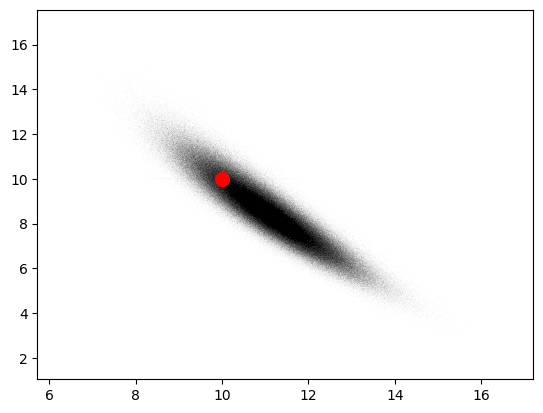

In [72]:

for alpha1, alpha2 in zip(ALPHA1_CHAINS, ALPHA2_CHAINS):
    plt.plot(alpha1, alpha2, 'k,', alpha=0.01)

plt.plot([ALPHA1], [ALPHA2], 'ro', markersize=10)

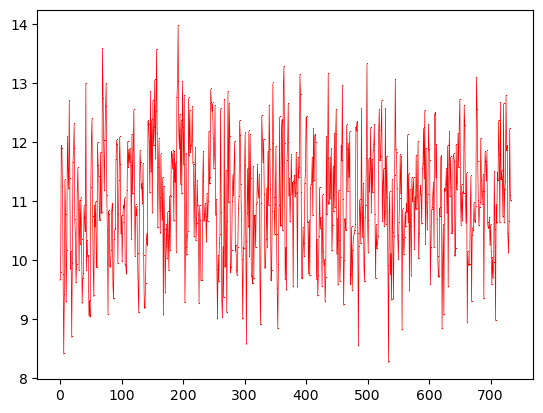

In [79]:
for chain in ALPHA1_CHAINS[:1]:
    plt.plot(chain, '-r,', alpha=1, lw=0.5)

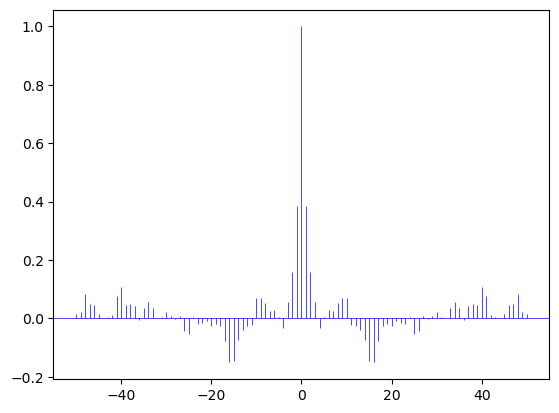

In [85]:
lag = len(ALPHA1_CHAINS[0])-1
lag = 50
corrected_alpha = ALPHA1_CHAINS[0] - ALPHA1_CHAINS[0].mean()
plt.acorr(corrected_alpha, maxlags=lag, color='b', lw=0.5)
plt.show()


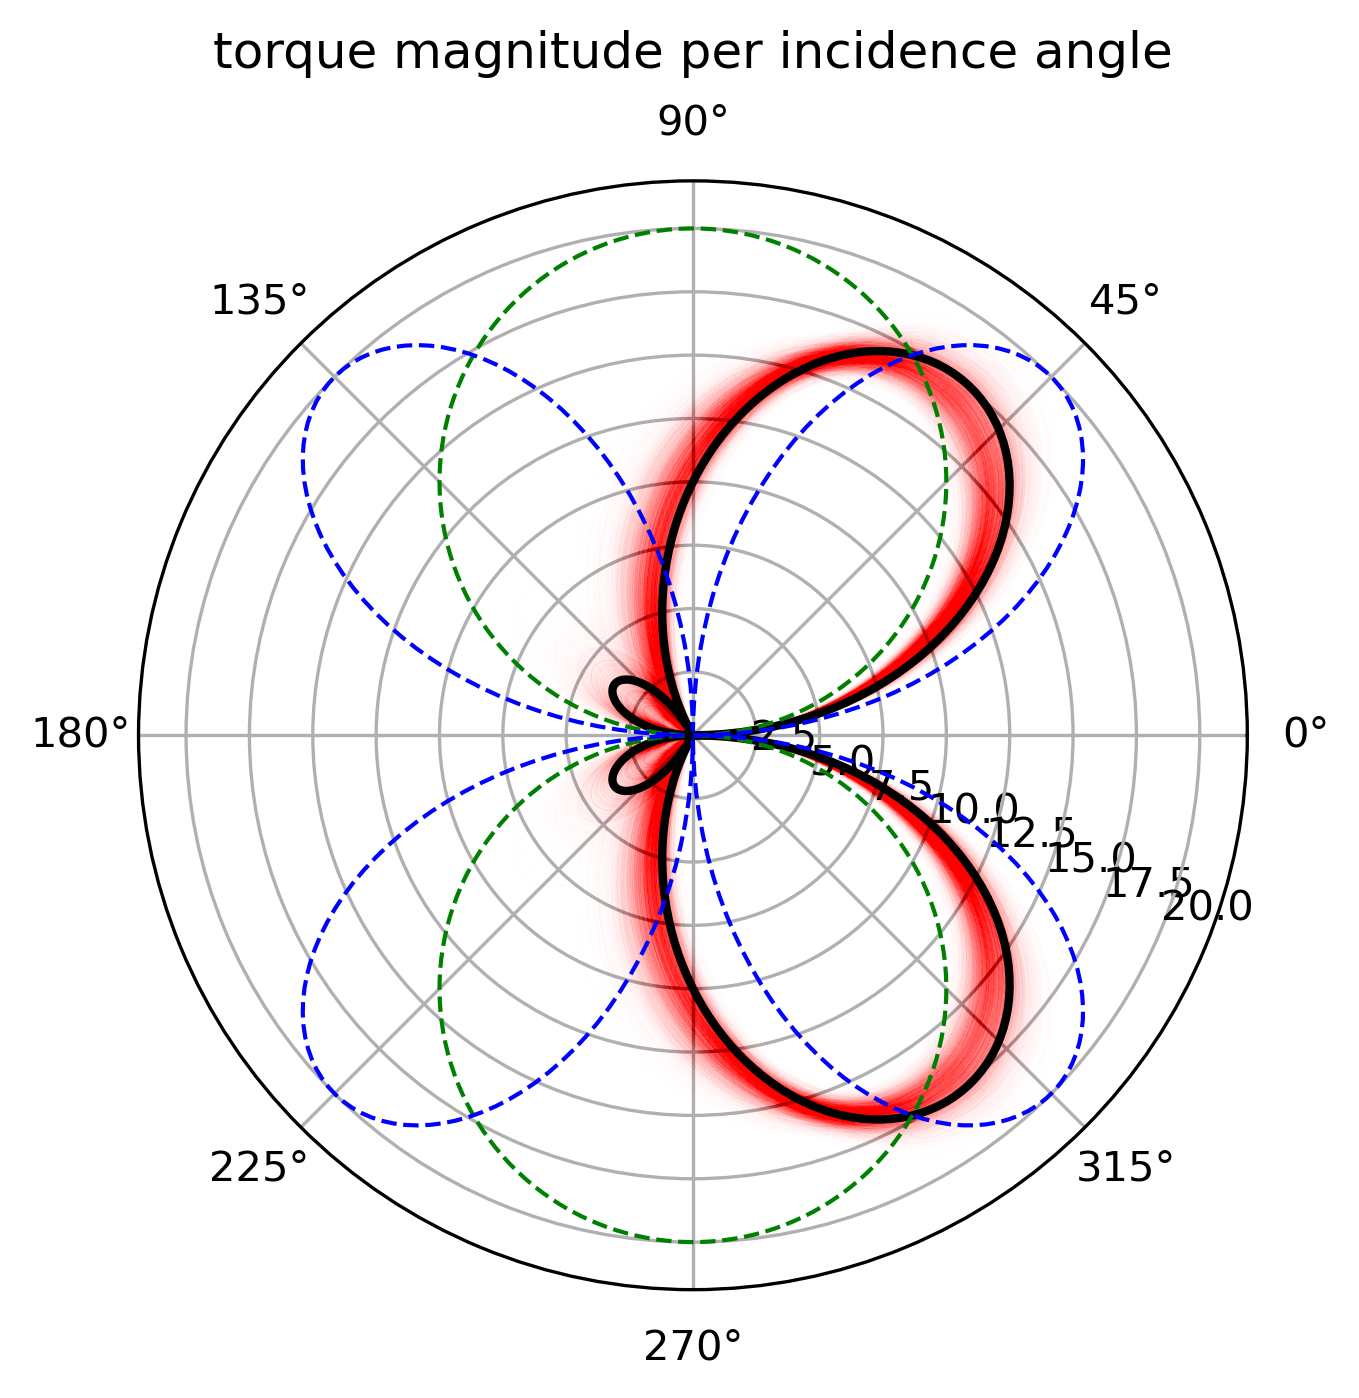

In [102]:
phi = np.linspace(0, 2*np.pi, 300)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, dpi=300)

n_chains = 10

for ALPHA1_CHAIN, ALPHA2_CHAIN in zip(ALPHA1_CHAINS[:n_chains], ALPHA2_CHAINS[:n_chains]):
    for a1, a2 in zip(ALPHA1_CHAIN, ALPHA2_CHAIN):
        torque = np.abs(TORQUE(phi, [a1, a2]))
        plt.plot(phi, torque, 'r', alpha=0.01, lw=0.1)
    torque_true = np.abs(TORQUE(phi, [ALPHA1, ALPHA2]))
plt.plot(phi, torque_true, 'k', lw=2)

torque_perp = np.abs(TORQUE(phi, [2*ALPHA1, 0.]))
plt.plot(phi, torque_perp, 'g', lw=1, ls='--')

torque_tang = np.abs(TORQUE(phi, [0., 2*ALPHA2]))
plt.plot(phi, torque_tang, 'b', lw=1, ls='--')

ax.set_rlabel_position(-22.5)  # Move radial labels away from plotted line
ax.grid(True)

ax.set_title("torque magnitude per incidence angle", va='bottom')
plt.show()